# Sources, entropy rates and typicality

Time units matter: one subsampled output spans two original transitions. Invertible transforms can preserve entropy rate while destroying a first-order Markov description.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.sources import stationary, entropy_rate, transformation_examples

transition = np.array([[1 / 3, 2 / 3], [0.5, 0.5]])
print("Stationary law:", stationary(transition))
print("Original bits/output:", entropy_rate(transition))
print("Subsampled bits/output:", entropy_rate(transition @ transition))
print({k: v for k, v in transformation_examples().items() if "conditional_mi" in k})

Stationary law: [0.42857143 0.57142857]
Original bits/output: 0.9649839288804956
Subsampled bits/output: 0.9846718865884683
{'ordinary_conditional_mi': 9.152647153756907e-17, 'swapped_conditional_mi': 0.000540786411807956, 'summed_conditional_mi': 0.24301919275048753}


Weak typicality controls surprisal; strong typicality controls every empirical frequency. Under a uniform source, all sequences have identical surprisal, including very unbalanced sequences.

In [3]:
from information_lab.sources import typicality_counts

uniform = typicality_counts([0.25] * 4, 16, 10000, 41, 0.1, 0.2)
skewed = typicality_counts([0.6, 0.25, 0.1, 0.05], 16, 10000, 41, 0.1, 0.2)
print("Uniform weak/strong fractions:", uniform["weak"].mean(), uniform["strong"].mean())
print("Skewed weak/strong fractions:", skewed["weak"].mean(), skewed["strong"].mean())

Uniform weak/strong fractions: 1.0 0.0154
Skewed weak/strong fractions: 0.2544 0.0809


**Recorded configuration**

{
  "family": "sources",
  "id": "uniform_16",
  "task": "typicality",
  "probability": [
    0.25,
    0.25,
    0.25,
    0.25
  ],
  "blocklength": 16,
  "trials": 10000,
  "weak_tolerance": 0.1,
  "strong_tolerance": 0.2
}
{
  "weak_fraction": 1.0,
  "strong_fraction": 0.0154,
  "true_entropy_bits": 2.0,
  "scope": "Multinomial symbol counts are the exact sufficient statistics of independent length-n IID source sequences. Strong tolerance follows the exercise's absolute epsilon/alphabet convention."
}


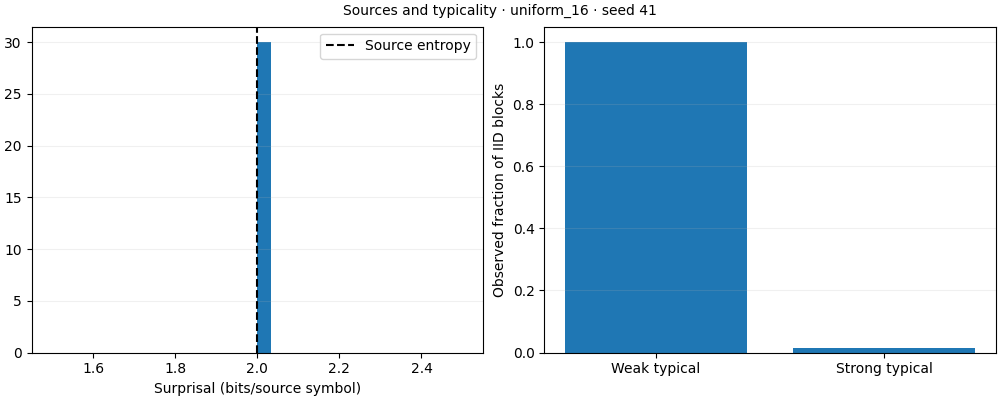

In [4]:
record, path = query("sources", task="typicality", probability=[0.25] * 4, blocklength=16)[0]
measured(record)
preview(record)

In [5]:
records = query("sources", task="typicality", probability=[0.6, 0.25, 0.1, 0.05])
records = sorted(records, key=lambda rp: rp[0]["config"]["blocklength"])
for metric in ["weak_fraction", "strong_fraction"]:
    plt.plot(
        [r["config"]["blocklength"] for r, _ in records],
        [r["metrics"][metric] for r, _ in records],
        "o-",
        label=metric,
    )
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("IID blocklength")
plt.ylabel("Observed typical fraction")
plt.legend()
plt.show()